In [220]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_csv("./TelcoCustomer.csv")
df.shape
df.head(10)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


------------ Name:MonthlyCharges -------------
Min: 18.25
Q1: 35.5
Median: 70.35
Q3: 89.85
Max: 118.75
------------ Name:tenure -------------
Min: 0
Q1: 9.0
Median: 29.0
Q3: 55.0
Max: 72

MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64
Missing Value Counts (0)


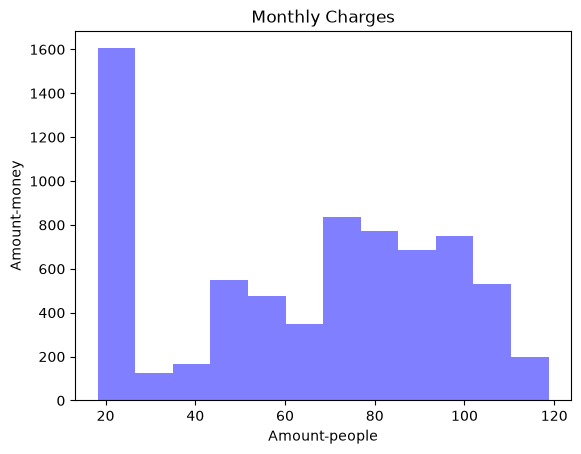

In [221]:
def func(column_name): 
    min = np.min(df[column_name])
    q1 = np.percentile(df[column_name], 25)
    med = np.median(df[column_name])
    q3 = np.percentile(df[column_name], 75)
    max = np.max(df[column_name])

    print(f'------------ Name:{column_name} -------------')
    print(f"Min: {min}")
    print(f"Q1: {q1}")
    print(f"Median: {med}")
    print(f"Q3: {q3}")
    print(f"Max: {max}")

func("MonthlyCharges")
func("tenure")

print()
print(df.MultipleLines.value_counts())
print()
print(df.InternetService.value_counts())
print()
print(df.Contract.value_counts())
print()
print(df.PaymentMethod.value_counts())

print(f"Missing Value Counts ({df.value_counts().isna().sum()})")

# a large majority of people pay between 18.25 and 28.30 dollars for the service.
plt.hist(df['MonthlyCharges'], bins=12, color='blue', alpha=0.5)
plt.title("Monthly Charges")
plt.xlabel("Amount-people")
plt.ylabel("Amount-money")
plt.show()


In [222]:
# Had a crap ton of help from AI on this...

import pandas as pd
from pandas.api.types import is_numeric_dtype, is_string_dtype

df.rename(columns={'Churn': 'LeftLastMonth'}, inplace=True)

def average_values(df_in, column_name):
    if column_name not in df_in.columns:
        return None
        
    if is_string_dtype(df_in[column_name]):
        fill_value = df_in[column_name].mode().iloc[0]

    elif is_numeric_dtype(df_in[column_name]):
        fill_value = df_in[column_name].median()

    else:
        return None
        
    df_in[column_name] = df_in[column_name].fillna(fill_value)
    return fill_value

def missing_values(df_in):
    null_values = df_in.isna().sum()
    print(null_values.to_string())
    
    pct_missing = null_values.sum() / (len(df_in) * len(df_in.columns))
    print(f"\nTotal Percentage of missing values: {pct_missing * 100:.2f}%\n")

def unique_values(df_in, column_name):
    if column_name in df_in.columns:
        print(df_in[column_name].unique())
        
    else:
        print(f"Column '{column_name}' not found.")

fill_monthly = average_values(df, "MonthlyCharges")
fill_lines = average_values(df, "Multiplelines")
fill_churn = average_values(df, "Leftlastmonth")

unique_values(df, 'Customerid')
columns_to_drop = ["Paperlessbilling", "Paymentmethod", "Customerid", "Onlinesecurity", "Onlinebackup", "Deviceprotection"]

columns_to_drop = [col for col in columns_to_drop if col in df.columns]
data = df.drop(columns=columns_to_drop).copy()

missing_values(df)
encoded_data = pd.get_dummies(data, drop_first=True)

print(list(df.columns))



Column 'Customerid' not found.
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
LeftLastMonth       0

Total Percentage of missing values: 0.00%

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'LeftLastMonth']


In [225]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

if df['LeftLastMonth'].dtype == 'O' or df['LeftLastMonth'].dtype == 'string':
    df['LeftLastMonth_cleaned'] = df['LeftLastMonth'].astype(str).str.strip().str.lower()
    df['LeftLastMonth_numeric'] = df['LeftLastMonth_cleaned'].map({'yes': 1, 'true': 1, 'no': 0, 'false': 0})
else:
    df['LeftLastMonth_numeric'] = pd.to_numeric(df['LeftLastMonth'], errors='coerce')

df_clean = df[['TotalCharges', 'LeftLastMonth_numeric']].dropna()

if len(df_clean) >= 2:
    r, p = stats.pearsonr(df_clean['TotalCharges'], df_clean['LeftLastMonth_numeric'])
    print(f'Pearson r correlation coefficient:   {r:.3f}')
    print(f'p-value:                             {p:.3f}')
else:
    print(f"Error: df_clean still has {len(df_clean)} rows.")
    print("Sample values in TotalCharges:", df['TotalCharges'].head().tolist())
    print("Sample values in LeftLastMonth:", df['LeftLastMonth'].head().tolist())
    print("--- Raw TotalCharges ---")



Pearson r correlation coefficient:   -0.199
p-value:                             0.000


Based off of the data the largest correlation for why people are leaving the service is due to tenure. We chose correlation because we figured that the data for tenure could be the reason that people are churning.